## Task 1: Computing Eigenvalues and Eigenvectors of a Matrix

In [6]:
import numpy as np

In [16]:
def eigen(M):
    eigenvalues, eigenvectors = np.linalg.eig(M)
    if np.allclose(eigenvalues.imag, 0):
        eigenvalues, eigenvectors = eigenvalues.real, eigenvectors.real
    return eigenvalues, eigenvectors

In [25]:
M = np.array([[ 1, 0, 3],
                 [-1, 4, 1],
                 [ 1, 0, 3]])

In [26]:
eigen(M)

(array([4., 0., 4.]),
 array([[ 0.        , -0.90453403, -0.70272837],
        [ 1.        , -0.30151134, -0.11111111],
        [ 0.        ,  0.30151134, -0.70272837]]))

Check the results

In [27]:
eigenvalues, eigenvectors = eigen(M)
for i in range(len(eigenvalues)):
    v = eigenvectors[:, i] 
    lambda1 = eigenvalues[i]
    left = M @ v
    right = lambda1 * v
    print("Av = lambda*v:", i+1, "row:", np.allclose(left, right))

Av = lambda*v: 1 row: True
Av = lambda*v: 2 row: True
Av = lambda*v: 3 row: True


## Task 2: Implementation of Image Dimensionality Reduction Using Principal Component Analysis (PCA: Image Compression)

In [ ]:
import matplotlib.pyplot as plt

(396, 600, 3)


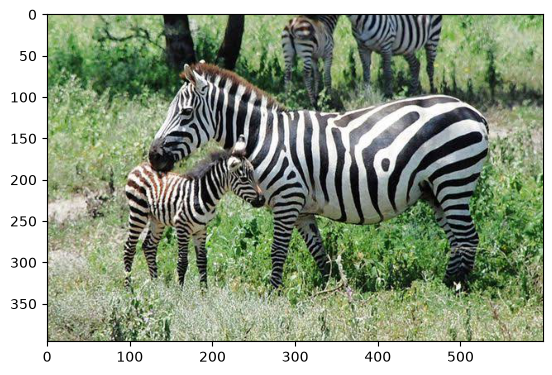

In [35]:
img = plt.imread("zebra.jpeg")

plt.imshow(img)
print(img.shape)

In [37]:
img_sum = img.sum(axis=2)
print(img_sum.shape)
img_bw = img_sum/img_sum.max()
print(img_bw.max())

(396, 600)
1.0


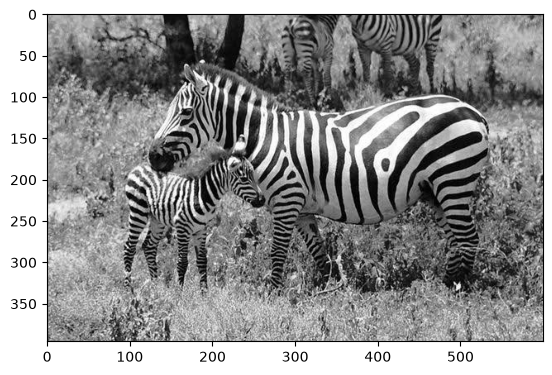

In [38]:
plt.imshow(img_bw, cmap="gray")

In [40]:
!mamba install scikit-learn

mambajs 0.21.4

Specs: xeus-python, numpy, matplotlib, pillow, ipywidgets>=8.1.6, ipyleaflet, scipy, scikit-learn
Channels: emscripten-forge-4x, conda-forge

Solving environment...
Solving took 1.338 seconds
  Name                Version     Build                Channel
----------------------------------------------------------------------------
+ brotli-python       1.2.0       py313h8faef1e_3      emscripten-forge-4x
+ ca-certificates     2026.10.23  hbd8a1cb_0           conda-forge
+ certifi             2026.10.23  pyhd8ed1ab_3         conda-forge
+ charset-normalizer  3.5.1       pyhd8ed1ab_0         conda-forge
+ idna                3.20        pyh5ded981_0         conda-forge
+ joblib              1.6.0       py313h57e9779_0      emscripten-forge-4x
+ narwhals            2.28.0      pyh5ded981_0         conda-forge
+ pysocks             1.7.1       py313h1804a44_3      emscripten-forge-4x
+ requests            2.34.2      pyhcf101f3_0         conda-forge
+ scikit-learn        1.9

In [41]:
from sklearn.decomposition import PCA

In [43]:
pca = PCA()
pca.fit(img_bw)

cum_var = np.cumsum(pca.explained_variance_ratio_)
k = np.argmax(cum_var >= 0.95) + 1
print(k)

109


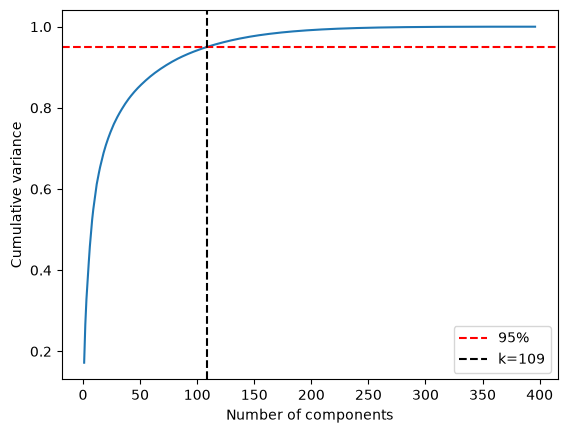

In [45]:
plt.plot(range(1, len(cum_var) + 1), cum_var)
plt.axhline(0.95, color="red", linestyle="--", label="95%")
plt.axvline(k, color="black", linestyle="--", label=f"k={k}")
plt.xlabel("Number of components")
plt.ylabel("Cumulative variance")
plt.legend()
plt.show()

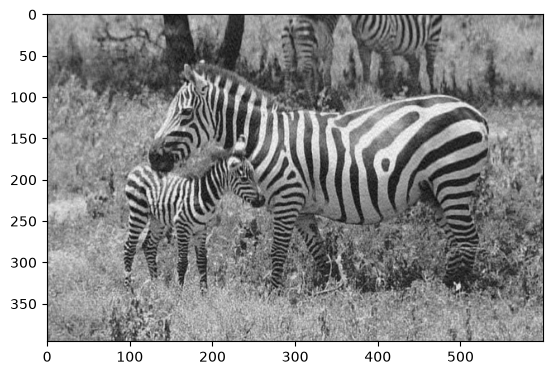

In [46]:
pca_k = PCA(n_components=k)
compressed = pca_k.fit_transform(img_bw)
reconstructed = pca_k.inverse_transform(compressed)

plt.imshow(reconstructed, cmap="gray")
plt.show()

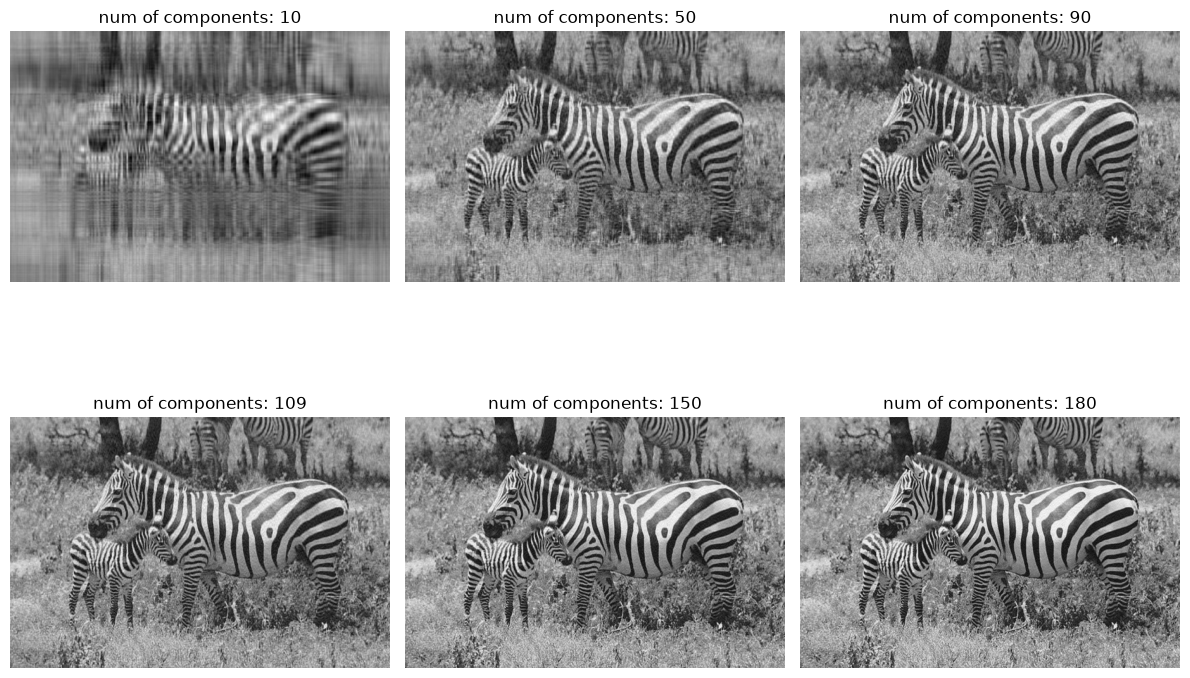

In [52]:
k_list = [10, 50, 90, 109, 150, 180]
fig, axes = plt.subplots(2, 3, figsize=(12, 9))
axes = axes.flatten()

for i, k in enumerate(k_list):
    pca_k = PCA(n_components=k)
    compressed = pca_k.fit_transform(img_bw)
    reconstructed = pca_k.inverse_transform(compressed)
    axes[i].imshow(reconstructed, cmap="gray")
    axes[i].set_title(f"num of components: {k}")
    axes[i].axis("off")

plt.tight_layout()
plt.show()

## Task 3: Using Diagonalization, Eigenvalues and Eigenvectors in Cryptography

In [53]:
def encrypt_message(message, key_matrix):

    message_vector = np.array([ord(char) for char in message])
    eigenvalues, eigenvectors = np.linalg.eig(key_matrix)
    diagonalized_key_matrix = np.dot(np.dot(eigenvectors, np.diag(eigenvalues)), np.linalg.inv(eigenvectors))
    encrypted_vector = np.dot(diagonalized_key_matrix, message_vector)
    return encrypted_vector

In [60]:
def decrypt_message(encrypted_vector, key_matrix):
    eigenvalues, eigenvectors = np.linalg.eig(key_matrix)
    inverse_key_matrix = np.dot(np.dot(eigenvectors, np.diag(1/eigenvalues)), np.linalg.inv(eigenvectors))
    decrypted_vector = np.real((np.dot(inverse_key_matrix, encrypted_vector)))
    decrypted_message = "".join(chr(int(round(x))) for x in decrypted_vector)
    return decrypted_message

In [62]:
message = "Hello, World!"
key_matrix = np.random.randint(0, 256, (len(message), len(message)))
encrypted = encrypt_message(message, key_matrix)
decrypted = decrypt_message(encrypted, key_matrix)

print(message)
print(encrypted)
print(decrypted)

Hello, World!
[148168.+1.36807926e-11j 140365.+2.70209966e-11j 148008.+4.02802791e-12j
 146410.+3.62923025e-11j 138387.+1.30379318e-11j 139752.+6.81281420e-12j
 127893.+1.09516007e-11j 154801.+3.53603674e-11j 137473.+1.79898874e-11j
 116756.+9.42450284e-12j 136271.+1.75761142e-11j 106124.+1.82079629e-11j
 150475.+1.38033751e-11j]
Hello, World!
